# Dogs vs. Cats with CLIP zero-shot

This notebook classifies photos as cat or dog with CLIP and no training at all. Each image is compared
with the two text prompts "a photo of a cat." and "a photo of a dog.", and the closer one wins.
CLIP is the off-the-shelf model we compare against; our trained model is ConvNeXt-Tiny (see the README).

Run everything with Runtime > Run all.

- It uses the small **CLIP ViT-B/32** so it runs on a free Colab GPU (or CPU). The results in the
  README use the larger ViT-L/14, which reached 99.84% on the 5,000 validation images.
- No weights from this repo are needed. CLIP downloads from the open_clip model hub on first use.
- You can try the example images, upload your own, or run it on `data/dataset/val` if you have the dataset.

In [ ]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("open_clip") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "open_clip_torch"], check=True)

In [ ]:
import io
import urllib.request

import matplotlib.pyplot as plt
import open_clip
import torch
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"
model, _, preprocess = open_clip.create_model_and_transforms("ViT-B-32-quickgelu", pretrained="openai")
tokenizer = open_clip.get_tokenizer("ViT-B-32-quickgelu")
model = model.to(device).eval()

classes = ["cat", "dog"]
with torch.no_grad():
    text = model.encode_text(tokenizer([f"a photo of a {c}." for c in classes]).to(device))
    text = text / text.norm(dim=-1, keepdim=True)
print("running on", device)

In [ ]:
@torch.no_grad()
def predict(images):
    # returns P(dog) for a list of PIL images
    x = torch.stack([preprocess(im.convert("RGB")) for im in images]).to(device)
    feats = model.encode_image(x)
    feats = feats / feats.norm(dim=-1, keepdim=True)
    probs = (model.logit_scale.exp() * feats @ text.T).softmax(dim=-1)
    return probs[:, 1].cpu().numpy()


def show(images, titles):
    p_dog = predict(images)
    fig, axes = plt.subplots(1, len(images), figsize=(4 * len(images), 4), squeeze=False)
    for ax, im, t, p in zip(axes[0], images, titles, p_dog):
        ax.imshow(im)
        ax.set_title(f"{t}\n{'dog' if p > 0.5 else 'cat'}  (P(dog) = {p:.3f})", fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## Example images

Freely licensed photos from Wikimedia Commons (author and license on each file page):
[cat 1](https://commons.wikimedia.org/wiki/File:Cat03.jpg),
[cat 2](https://commons.wikimedia.org/wiki/File:Cat_November_2010-1a.jpg),
[dog 1](https://commons.wikimedia.org/wiki/File:YellowLabradorLooking_new.jpg),
[dog 2](https://commons.wikimedia.org/wiki/File:Golde33443.jpg).

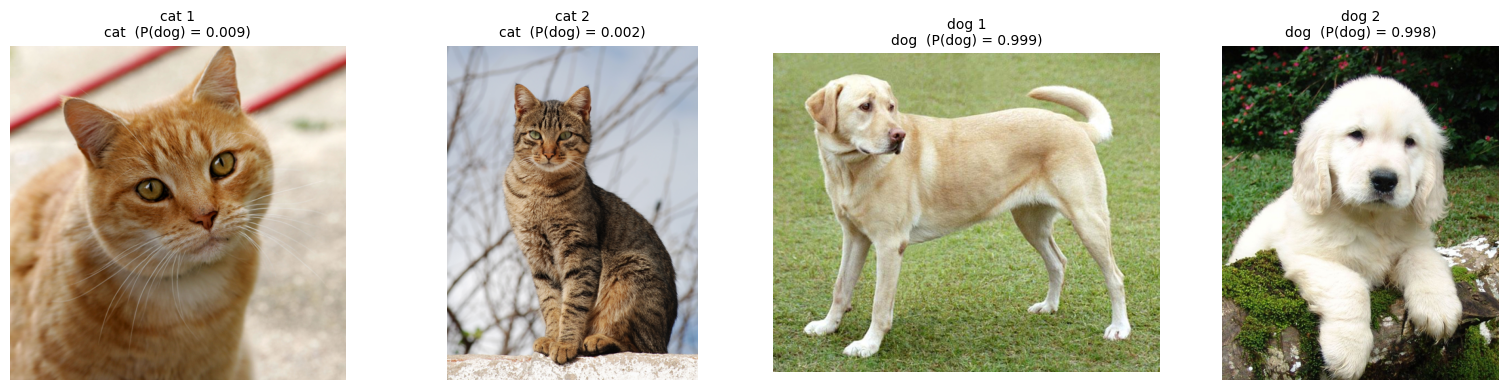

In [ ]:
urls = {
    "cat 1": "https://upload.wikimedia.org/wikipedia/commons/3/3a/Cat03.jpg",
    "cat 2": "https://upload.wikimedia.org/wikipedia/commons/4/4d/Cat_November_2010-1a.jpg",
    "dog 1": "https://upload.wikimedia.org/wikipedia/commons/2/26/YellowLabradorLooking_new.jpg",
    "dog 2": "https://upload.wikimedia.org/wikipedia/commons/6/6e/Golde33443.jpg",
}


def load_url(url):
    req = urllib.request.Request(url, headers={"User-Agent": "ie4483-demo/1.0"})
    with urllib.request.urlopen(req, timeout=30) as r:
        im = Image.open(io.BytesIO(r.read())).convert("RGB")
    im.thumbnail((512, 512))
    return im


examples = [load_url(u) for u in urls.values()]
show(examples, list(urls))

## Your own images (Colab only)

Run the cell below and pick one or more image files.

In [ ]:
try:
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        ims = [Image.open(io.BytesIO(b)).convert("RGB") for b in uploaded.values()]
        show(ims, list(uploaded))
except ImportError:
    print("Not on Colab, skipping upload. Use show([Image.open(path)], [path]) instead.")

## Optional: accuracy on the validation set

If the dataset is at `data/dataset/val/{cat,dog}` (from the repo root), this computes the accuracy.
Set `LIMIT` to a smaller number for a quick check.

In [ ]:
from pathlib import Path

VAL_DIR = Path("data/dataset/val")
if not VAL_DIR.exists():
    VAL_DIR = Path("../data/dataset/val")  # when the notebook is run from notebooks/
LIMIT = 500  # images per class, None for all 2,500

if VAL_DIR.exists():
    paths, labels = [], []
    for y, c in enumerate(classes):
        files_c = sorted((VAL_DIR / c).glob("*.jpg"))[:LIMIT]
        paths += files_c
        labels += [y] * len(files_c)
    correct = 0
    for i in range(0, len(paths), 64):
        batch = [Image.open(p) for p in paths[i:i + 64]]
        pred = (predict(batch) > 0.5).astype(int)
        correct += int((pred == labels[i:i + 64]).sum())
    print(f"val accuracy on {len(paths)} images: {correct / len(paths):.4f}")
else:
    print("data/dataset/val not found, skipped")